# 11 · 轨迹模型，以及和图像模型的融合

**目的。**游戏里拿到的不只是一张图，而是**整个书写过程**：每一笔的先后、每一笔的方向。画成 28×28 的图时这些信息全丢了。notebook 10 的错误审查发现，剩下的"模型读错"里有好几类在图上几乎一样、但**笔顺完全不同**：

- 上圈不封口的 8 和 6：6 从上往下一笔绕圈，结束在圈里；这种 8 绕完下圈还要回到顶部；
- 平顶的 3 和 7：3 的第二段是弯回来的；
- 带勾的 1 和 7。

文献里（07 文档 1.3、1.4 节），单用轨迹的模型不一定比图像好（Corr 等人 [7]：轨迹 95.9%，图像 98.5%），但**两者融合**能明显减少错误（Vinciarelli 和 Perrone [14]：单个数字上错误减少 43%）。这一本回答三个问题：

1. 只用 Pendigits 训练部分（24 人，触控笔）训练的轨迹模型，在触控笔和手指（完全没见过）上各有多准？
2. 和方案 C 的图像模型融合后，错误能减少多少？减少的是不是 notebook 10 里那几类？
3. 代价：模型多大、多慢？

**和 notebook 09 的公平比较。**图像模型就是 09 的方案 C（两个种子），它的训练数据里也有同样的 24 人。轨迹模型只用这 24 人（加增强），**不用任何新数据**。Corr（手指）仍然只做测试。方案按验证数据挑选（Pendigits val + Corr dev），测试集最后报告一次。

In [1]:
import json, pickle, sys, time
from multiprocessing import Pool
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import keras
from keras import layers

sys.path.insert(0, '.')
import evaluate, synth, trajectory

REAL = Path('cache/real'); RAW = Path('cache/raw'); RESULTS = Path('results'); MODEL_DIR = Path('cache/models')
SEEDS = [42, 43]
EPOCHS, STEPS, BATCH, SMOOTHING = 16, 470, 128, 0.1         # the same budget as the image models (notebook 09)
N_AUG = 19                                                   # augmented copies of every Pendigits train sample
plt.rcParams['figure.dpi'] = 110

## 1. 数据：按书写顺序的笔迹

- **触控笔**：Pendigits 的原始轨迹本来就是按时间记录的，笔画顺序可靠。
- **手指**：按 notebook 10 发现的 `Z_FOK_GLYPH` 重新排列 Corr 的笔画顺序（`trajectory.corr_strokes_in_order`）。下面先检查：重新解析出的笔画和 notebook 07 存下的**完全是同一批**，只是多笔数字的先后不同。

In [2]:
d = np.load(REAL / 'real_digits.npz')
meta = pd.DataFrame({k: d[k] for k in ['source', 'device', 'writer', 'split']}); meta['label'] = d['y']
y = d['y']
with open(REAL / 'real_strokes.pkl', 'rb') as f:
    strokes_07 = [s['strokes'] for s in pickle.load(f)]

k_corr = np.flatnonzero(meta.source == 'corr')
corr_ordered = trajectory.corr_strokes_in_order(RAW / 'corr')
assert len(corr_ordered) == len(k_corr)
same_ink = all(sorted(map(lambda s: np.asarray(s).tobytes(), a)) == sorted(map(lambda s: np.asarray(s).tobytes(), strokes_07[i]))
               for a, i in zip(corr_ordered, k_corr))
strokes = list(strokes_07)
for a, i in zip(corr_ordered, k_corr):
    strokes[i] = a
moved = sum(len(a) > 1 and any(not np.array_equal(p, q) for p, q in zip(a, strokes_07[i])) for a, i in zip(corr_ordered, k_corr))
print('same strokes as notebook 07:', same_ink, '| multi-stroke Corr digits whose order changed:', moved)

same strokes as notebook 07: True | multi-stroke Corr digits whose order changed: 2203


### 1.1 编码

每个数字变成 64 个点的序列（`trajectory.encode`）：点沿着笔迹等距分布，按长度分给各笔；每个点 5 个特征：位置 `x, y`（以外框中心为原点、按长边缩放，保留长宽比），到同一笔下一个点的位移 `dx, dy`（方向信息），以及"这里提过笔"的标记。**不用时间**：触控笔、手指、鼠标的速度差别很大，用了反而会把工具的差别学进去。

下图：几个数字的编码，颜色从浅到深是书写的先后，圆圈是每一笔的起点。

(31066, 64, 5)


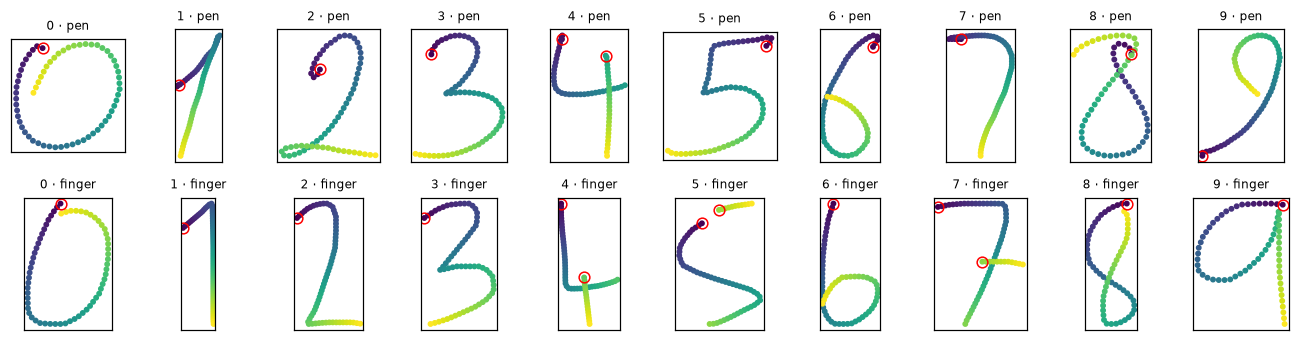

In [3]:
def encode_all(idx, src=None):
    src = strokes if src is None else src
    with Pool() as pool:
        return np.stack(pool.map(trajectory.encode, [src[i] for i in idx], chunksize=200))

X = encode_all(range(len(strokes)))                       # every real sample, writing order
print(X.shape)

def show_seq(ax, e, title):
    ax.scatter(e[:, 0], e[:, 1], c=np.arange(len(e)), cmap='viridis', s=8)
    for j in np.flatnonzero(e[:, 4] == 1).tolist() + [0]:
        ax.plot(e[j, 0], e[j, 1], 'o', mfc='none', mec='red', ms=7)
    ax.set_aspect('equal'); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=8)

fig, axes = plt.subplots(2, 10, figsize=(12, 3.2))
for r, src_name in enumerate(['pendigits', 'corr']):
    for c in range(10):
        i = np.flatnonzero((meta.source == src_name) & (y == c) & (meta.split != 'train'))[3]
        show_seq(axes[r, c], X[i], f'{c} · {"pen" if r == 0 else "finger"}')
plt.tight_layout(); plt.show()

### 1.2 训练数据

- **Pendigits 训练部分**（24 人，5998 个）：每个样本 1 份原样 + 19 份随机仿射变换（旋转 ±10°、倾斜 ±0.35、缩放 0.8–1.2，和 notebook 09 的笔画增强相同，`augstrokes.transform`）。
- **对照（消融）**：再加上合成的"模板笔迹"（notebook 06 的书写者模型，`synth.template_strokes`，每个数字 2–3 种写法、按真实的笔顺设计），占 30%。它能补上 24 个人里没有的写法吗？

In [4]:
k_tr = np.flatnonzero((meta.source == 'pendigits') & (meta.split == 'train'))
with Pool() as pool:
    parts = pool.starmap(trajectory.encode_variants, [(strokes[i], 5000 + j, N_AUG) for j, i in enumerate(k_tr)], chunksize=50)
X_pen = np.concatenate(parts); y_pen = np.repeat(y[k_tr], N_AUG + 1)

rng = np.random.default_rng(11)
tmpl_strokes, y_tmpl = [], []
for w in range(2000):                                      # 2000 template writers x 10 digits x 3
    writer = synth.make_writer(rng)
    for dgt in np.repeat(np.arange(10), 3):
        tmpl_strokes.append(synth.template_strokes(int(dgt), writer, rng)); y_tmpl.append(dgt)
with Pool() as pool:
    X_tmpl = np.stack(pool.map(trajectory.encode, tmpl_strokes, chunksize=500))
y_tmpl = np.array(y_tmpl)
print('pen', X_pen.shape, '| templates', X_tmpl.shape)

def part(source, split):
    k = np.flatnonzero((meta.source == source) & (meta.split == split))
    return k
SPLITS = {'val: pen': part('pendigits', 'val'), 'val: finger': part('corr', 'dev'),
          'test: pen': part('pendigits', 'test'), 'test: finger': part('corr', 'test')}

pen (119960, 64, 5) | templates (60000, 64, 5)


## 2. 轨迹模型

两种常见结构，参数量都和图像 CNN（107k）相当：

- **1D CNN**：沿着点序列做卷积，和图像 CNN 一样的"卷积 + 池化 + 全局平均"结构，浏览器里很快；
- **双向 GRU**：循环网络，从前往后、从后往前各读一遍，是在线手写识别的经典结构 [12]，但浏览器里慢一些。

训练预算、优化器、label smoothing 都和图像模型相同。每个配置两个种子。

In [5]:
def build_traj(kind):
    inp = layers.Input((trajectory.N, trajectory.FEATURES))
    if kind == 'cnn1d':
        h = inp
        for f in [48, 48]:
            h = layers.Conv1D(f, 5, padding='same', activation='relu')(h)
        h = layers.MaxPooling1D()(h)
        for f in [96, 96]:
            h = layers.Conv1D(f, 5, padding='same', activation='relu')(h)
        h = layers.MaxPooling1D()(h)
        h = layers.Conv1D(96, 3, padding='same', activation='relu')(h)
        h = layers.GlobalAveragePooling1D()(h)
    else:
        h = layers.Bidirectional(layers.GRU(64, return_sequences=True))(inp)
        h = layers.Bidirectional(layers.GRU(64))(h)
    h = layers.Dropout(0.3)(h)
    h = layers.Dense(64, activation='relu', name='embedding')(h)
    return keras.Model(inp, layers.Dense(10, activation='softmax', name='classifier')(h), name=kind)

def dataset(with_tmpl, seed):
    def one(x, yy):
        return tf.data.Dataset.from_tensor_slices((x, tf.one_hot(yy, 10))).shuffle(len(x), seed=seed).repeat()
    ds = one(X_pen, y_pen)
    if with_tmpl:
        ds = tf.data.Dataset.sample_from_datasets([ds, one(X_tmpl, y_tmpl)], [0.7, 0.3], seed=seed)
    return ds.batch(BATCH).prefetch(4)

CONFIGS = {'cnn1d': ('cnn1d', False), 'bigru': ('bigru', False), 'cnn1d + templates': ('cnn1d', True)}

def train_one(name, seed):
    kind, with_tmpl = CONFIGS[name]
    path = MODEL_DIR / f"traj11_{name.replace(' + ', '_')}_s{seed}.keras"
    if path.exists():
        return keras.models.load_model(path), None
    keras.utils.set_random_seed(seed)
    m = build_traj(kind)
    m.compile(optimizer=keras.optimizers.Adam(keras.optimizers.schedules.CosineDecay(2e-3, STEPS * EPOCHS)),
              loss=keras.losses.CategoricalCrossentropy(label_smoothing=SMOOTHING))
    t0 = time.time()
    m.fit(dataset(with_tmpl, seed), steps_per_epoch=STEPS, epochs=EPOCHS, verbose=0)
    m.save(path)
    return m, time.time() - t0

traj, PT, rows = {}, {}, []
for name in CONFIGS:
    for seed in SEEDS:
        m, secs = train_one(name, seed)
        traj[(name, seed)] = m
        PT[(name, seed)] = m.predict(X, batch_size=2048, verbose=0)
        r = {'config': name, 'seed': seed, 'params': m.count_params(), 'train min': None if secs is None else round(secs / 60, 1)}
        r.update({k: float((PT[(name, seed)][idx].argmax(1) == y[idx]).mean()) for k, idx in SPLITS.items()})
        rows.append(r); print(name, seed, {k: f'{v:.4f}' for k, v in r.items() if isinstance(v, float)})
runs = pd.DataFrame(rows)

C:\Projects\Math-Run\.venv\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


cnn1d 42 {'train min': '2.9000', 'val: pen': '0.9813', 'val: finger': '0.9490', 'test: pen': '0.9914', 'test: finger': '0.9517'}


cnn1d 43 {'train min': '2.9000', 'val: pen': '0.9813', 'val: finger': '0.9521', 'test: pen': '0.9871', 'test: finger': '0.9548'}


bigru 42 {'train min': '22.6000', 'val: pen': '0.9793', 'val: finger': '0.9515', 'test: pen': '0.9857', 'test: finger': '0.9503'}


bigru 43 {'train min': '22.7000', 'val: pen': '0.9799', 'val: finger': '0.9488', 'test: pen': '0.9857', 'test: finger': '0.9494'}


cnn1d + templates 42 {'train min': '2.9000', 'val: pen': '0.9820', 'val: finger': '0.9663', 'test: pen': '0.9814', 'test: finger': '0.9689'}


cnn1d + templates 43 {'train min': '3.0000', 'val: pen': '0.9813', 'val: finger': '0.9695', 'test: pen': '0.9828', 'test: finger': '0.9703'}


### 2.1 结果：轨迹模型单独用

对照行是 notebook 09 的图像模型（方案 C）。

In [6]:
P9 = dict(np.load(REAL / 'probs09.npz'))
PI = {s: P9[f'C_{s}'] for s in SEEDS}                        # image model C, per seed
img_rows = [{'config': 'image CNN (09 C)', 'seed': s, **{k: float((PI[s][idx].argmax(1) == y[idx]).mean()) for k, idx in SPLITS.items()}}
            for s in SEEDS]
allruns = pd.concat([runs, pd.DataFrame(img_rows)], ignore_index=True)
cols = list(SPLITS)
mean = allruns.groupby('config', sort=False)[cols].mean() * 100
mean['val mean'] = mean[['val: pen', 'val: finger']].mean(1)
best_traj = mean.drop('image CNN (09 C)')['val mean'].idxmax()
print('trajectory config chosen on the validation data:', best_traj)
mean.round(2)

trajectory config chosen on the validation data: cnn1d + templates


C:\Users\alext\AppData\Local\Temp\ipykernel_18140\4165421169.py:8: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  mean['val mean'] = mean[['val: pen', 'val: finger']].mean(1)


,val: pen,val: finger,test: pen,test: finger,val mean
config,,,,,
cnn1d,98.13,95.06,98.93,95.33,96.59
bigru,97.96,95.01,98.57,94.98,96.49
cnn1d + templates,98.16,96.79,98.21,96.96,97.48
image CNN (09 C),99.57,98.78,98.17,98.78,99.17


### 2.2 笔顺有多重要：用 notebook 07 的（错误）笔顺测一次

同一个轨迹模型，在手指测试集上分别用正确的笔顺（`Z_FOK_GLYPH`）和 notebook 07 的顺序（`ZINDEX`，约一半多笔数字顺序是反的）测试。差别越大，说明模型越依赖笔顺，也说明这次更正的必要。

In [7]:
kt = SPLITS['test: finger']
multi = np.array([len(strokes[i]) > 1 for i in kt])
X_old = encode_all(kt, strokes_07)
order_rows = []
for s in SEEDS:
    m = traj[(best_traj, s)]
    p_new, p_old = PT[(best_traj, s)][kt], m.predict(X_old, batch_size=2048, verbose=0)
    for nm, p in [('writing order (Z_FOK_GLYPH)', p_new), ('notebook 07 order (ZINDEX)', p_old)]:
        ok = p.argmax(1) == y[kt]
        order_rows.append({'order': nm, 'seed': s, 'all %': 100 * ok.mean(), 'multi-stroke digits %': 100 * ok[multi].mean()})
print(f'finger test: {multi.sum()} of {len(kt)} digits have more than one stroke')
pd.DataFrame(order_rows).groupby('order').mean().drop(columns='seed').round(2)

finger test: 3096 of 14017 digits have more than one stroke


,all %,multi-stroke digits %
order,,
notebook 07 order (ZINDEX),96.12,91.51
writing order (Z_FOK_GLYPH),96.96,95.32


## 3. 融合

**做法：晚期融合。**两个模型各自给出 10 个数字的概率，取对数后加权平均再归一化：

$$\log p_\text{fused} = w \cdot \log p_\text{image} + (1 - w) \cdot \log p_\text{traj} + \text{const}$$

$w = 1$ 就是只用图像，$w = 0$ 只用轨迹。$w$ 在**验证数据**上选（0 到 1，步长 0.05）。

**公平比较。**每个种子单独配对：图像（种子 42）+ 轨迹（种子 42），图像（种子 43）+ 轨迹（种子 43），两对的结果取平均，和"只用图像"的两个种子平均比较。这样融合不会因为"多用了几个模型"而占便宜（多个模型平均本身就会提高准确率）。

C:\Users\alext\AppData\Local\Temp\ipykernel_18140\1941360336.py:14: Pandas4Warning: Starting with pandas version 4.0 all arguments of mean will be keyword-only.
  curve['val mean'] = curve[['val: pen', 'val: finger']].mean(1)


w chosen on the validation data: 0.55


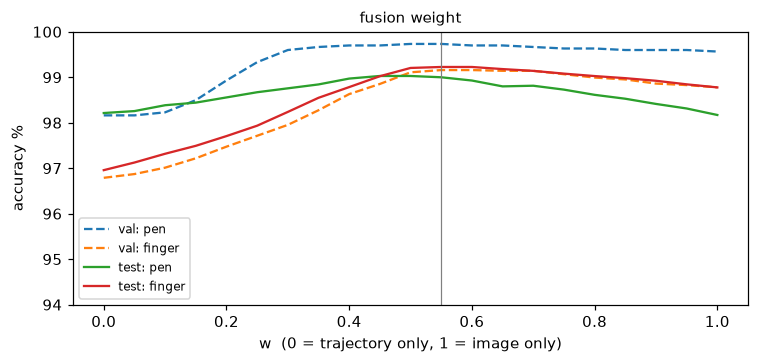

In [8]:
def fuse(p_img, p_traj, w):
    z = w * np.log(p_img + 1e-7) + (1 - w) * np.log(p_traj + 1e-7)
    z -= z.max(1, keepdims=True)
    e = np.exp(z); return e / e.sum(1, keepdims=True)

WS = np.round(np.arange(0, 1.0001, 0.05), 2)
curve = []
for w in WS:
    r = {'w': w}
    for k, idx in SPLITS.items():
        r[k] = np.mean([(fuse(PI[s][idx], PT[(best_traj, s)][idx], w).argmax(1) == y[idx]).mean() for s in SEEDS]) * 100
    curve.append(r)
curve = pd.DataFrame(curve).set_index('w')
curve['val mean'] = curve[['val: pen', 'val: finger']].mean(1)
W = float(curve['val mean'].idxmax())
print('w chosen on the validation data:', W)

fig, ax = plt.subplots(figsize=(7, 3.4))
for k in cols:
    ax.plot(curve.index, curve[k], '--' if k.startswith('val') else '-', label=k)
ax.axvline(W, color='gray', lw=0.8)
ax.set_xlabel('w  (0 = trajectory only, 1 = image only)'); ax.set_ylabel('accuracy %'); ax.set_ylim(94, 100)
ax.legend(fontsize=8); ax.set_title('fusion weight', fontsize=10); plt.tight_layout(); plt.show()

In [9]:
def summary(idx_name):
    idx = SPLITS[idx_name]
    out = {}
    for nm, f in [('image', lambda s: PI[s]), ('trajectory', lambda s: PT[(best_traj, s)]),
                  ('fusion', lambda s: fuse(PI[s], PT[(best_traj, s)], W))]:
        out[nm] = np.mean([(f(s)[idx].argmax(1) == y[idx]).mean() for s in SEEDS]) * 100
    out['error cut by fusion %'] = 100 * (1 - (100 - out['fusion']) / (100 - out['image']))
    return out

res = pd.DataFrame({k: summary(k) for k in ['test: pen', 'test: finger']}).round(2)
res

,test: pen,test: finger
image,98.17,98.78
trajectory,98.21,96.96
fusion,99.00,99.23
error cut by fusion %,45.31,36.73


### 3.1 两个模型的错误重叠吗

融合有用的前提是两个模型**错在不同的地方**。下面数一数测试集上：两个都错、只有图像错、只有轨迹错的样本（种子 42）。

In [10]:
overlap = {}
for k in ['test: pen', 'test: finger']:
    idx = SPLITS[k]
    ei = PI[42][idx].argmax(1) != y[idx]; et = PT[(best_traj, 42)][idx].argmax(1) != y[idx]
    ef = fuse(PI[42], PT[(best_traj, 42)], W)[idx].argmax(1) != y[idx]
    overlap[k] = {'both wrong': int((ei & et).sum()), 'only image wrong': int((ei & ~et).sum()),
                  'only trajectory wrong': int((~ei & et).sum()), 'fusion wrong': int(ef.sum())}
pd.DataFrame(overlap)

,test: pen,test: finger
both wrong,19,50
only image wrong,37,113
only trajectory wrong,46,386
fusion wrong,34,96


## 4. 每个数字

In [11]:
def per_digit(p, idx):
    pred = p[idx].argmax(1)
    return [100 * (pred[y[idx] == c] == c).mean() for c in range(10)]

tabs = {}
for k in ['test: pen', 'test: finger']:
    idx = SPLITS[k]
    for nm, f in [('image', lambda s: PI[s]), ('trajectory', lambda s: PT[(best_traj, s)]),
                  ('fusion', lambda s: fuse(PI[s], PT[(best_traj, s)], W))]:
        tabs[(k.split(': ')[1], nm)] = np.mean([per_digit(f(s), idx) for s in SEEDS], axis=0)
digit_table = pd.DataFrame(tabs).round(1); digit_table.index.name = 'digit'
digit_table

pen                   finger                  
       image trajectory fusion  image trajectory fusion
digit                                                  
0      100.0       96.1  100.0   99.8       99.1   99.8
1       98.6       99.7   99.3   97.9       94.2   98.8
2       99.3       99.7   99.7   98.9       97.4   99.0
3       98.8       99.4   99.4   98.4       96.9   98.5
4       93.4       97.3   96.3   98.7       99.8   99.9
5       99.6       98.2   99.4   99.3       97.6   99.5
6       99.1       97.9   98.8   99.5       98.5   99.6
7       96.4       95.3   98.4   98.9       95.8   99.5
8       99.7      100.0  100.0   97.0       99.0   99.2
9       97.0       98.7   98.8   99.4       91.4   98.5

## 5. 融合修好了 notebook 10 里的哪些错误

notebook 10 把方案 C（两个种子平均）的每个测试错误都归了类。这里看融合（两个种子的图像 + 两个种子的轨迹，各自平均后再融合）之后，每一类还剩多少错误，以及按写法分的几组（notebook 10 第 3.3 节的目视分组）。同时数一数融合**新引入**的错误：原来对、融合后错的样本。

In [12]:
audit = json.loads((RESULTS / '10_error_audit.json').read_text(encoding='utf-8'))
errs = pd.DataFrame(audit['errors']).set_index('id')
cat_col = 'final' if audit.get('reviewed') else 'screen'
pC = (PI[42] + PI[43]) / 2
pT = (PT[(best_traj, 42)] + PT[(best_traj, 43)]) / 2
pF = fuse(pC, pT, W)
errs['fusion right'] = pF[errs.index].argmax(1) == y[errs.index]

print(f'categories from notebook 10 ({cat_col}):')
print(errs.groupby(['set', cat_col])['fusion right'].agg(errors='size', fixed='sum').assign(
    share=lambda t: (100 * t.fixed / t.errors).round(0)))

groups = []
for g in audit['visual_pass']:
    ids = [i for i in g['ids'] if i in errs.index]
    if ids:
        groups.append({'pattern (notebook 10)': g['reason'][:70], 'category': g['category'], 'errors': len(ids),
                       'fixed by fusion': int(errs.loc[ids, 'fusion right'].sum())})
pd.DataFrame(groups)

categories from notebook 10 (screen):
                  errors  fixed  share
set    screen                         
finger ambiguous      56     28   50.0
       label           7      1   14.0
       model         105     73   70.0
pen    ambiguous      14      9   64.0
       model          47     24   51.0


,pattern (notebook 10),category,errors,fixed by fusion
0,writer pd-b13 writes every 4 the same one-stro...,model,24,11
1,flat-top 3 (written like a Z with a curl): peo...,model,12,8
2,1 with a foot and/or a short flag: people read...,model,6,5
3,4 written as an L plus a short vertical: peopl...,model,6,6
4,8 in one stroke whose two loops still cross cl...,model,8,7
5,crossed 7 (European style),model,3,3
6,2 with a small loop at the turn,model,2,1
7,slashed 0,model,1,1
8,5 with its top bar written apart,model,1,1
9,6 with a small loop,model,1,1


fixed by fusion: 135 | new errors made by fusion: 39


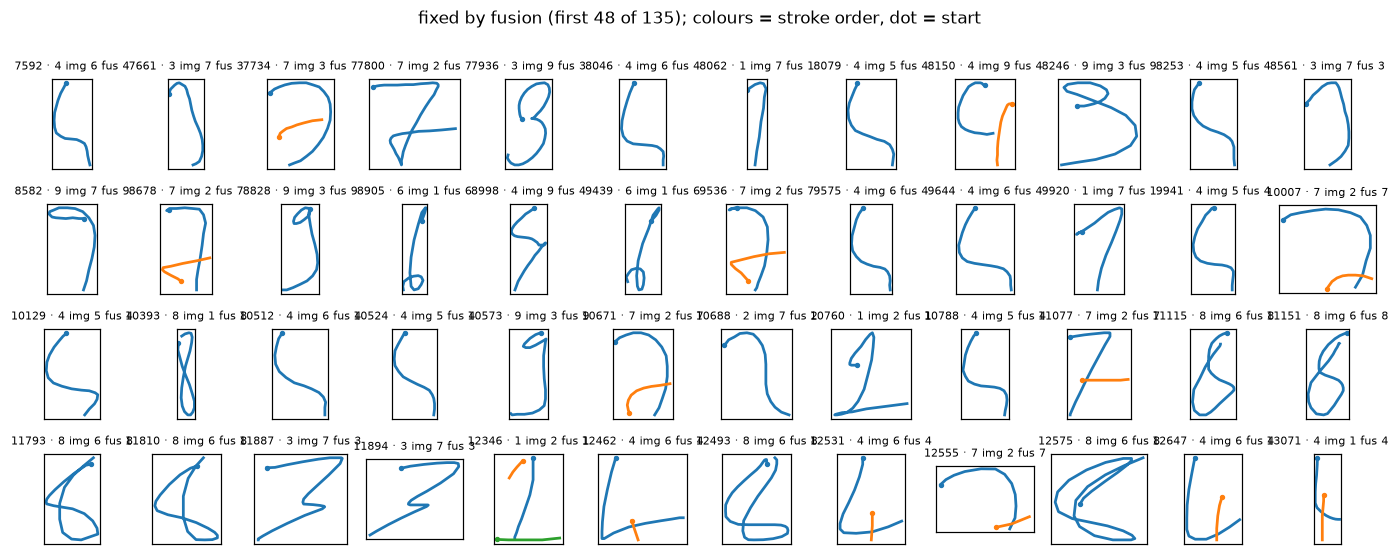

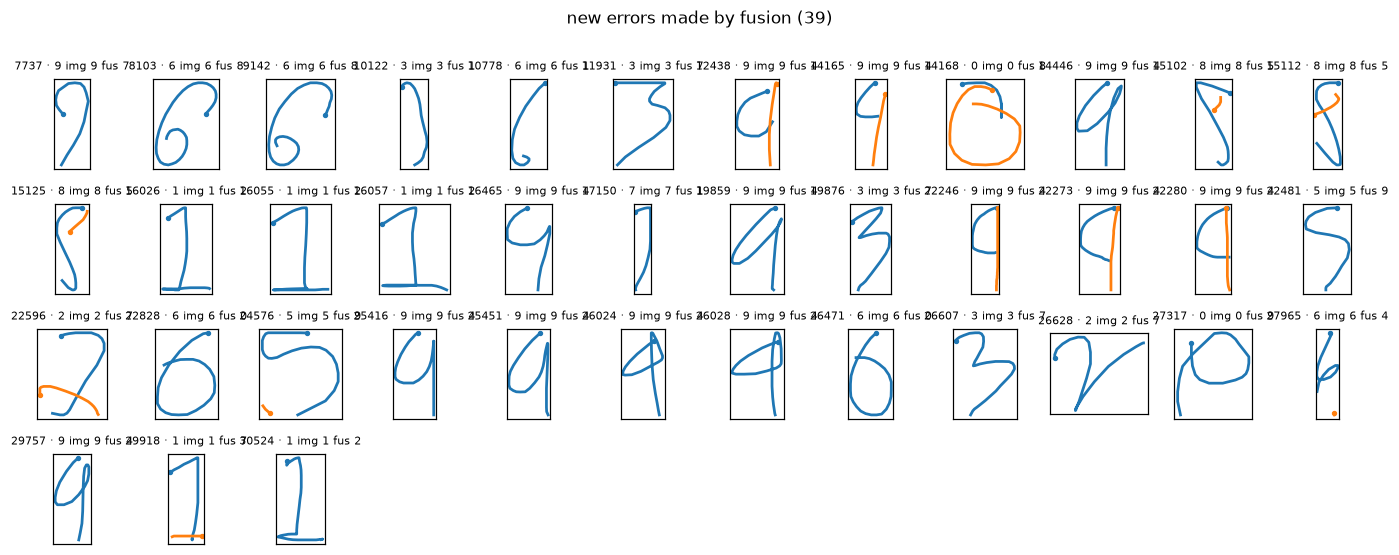

In [13]:
test_idx = np.concatenate([SPLITS['test: pen'], SPLITS['test: finger']])
new_err = test_idx[(pC[test_idx].argmax(1) == y[test_idx]) & (pF[test_idx].argmax(1) != y[test_idx])]
fixed = errs.index[errs['fusion right']]
print(f'fixed by fusion: {len(fixed)} | new errors made by fusion: {len(new_err)}')

def draw(ax, i, title):
    for j, s in enumerate(strokes[i]):
        s = np.asarray(s, float)
        ax.plot(s[:, 0], s[:, 1], '-', lw=1.8, color=plt.cm.tab10(j % 10)); ax.plot(*s[0], 'o', ms=2.5, color=plt.cm.tab10(j % 10))
    ax.set_aspect('equal'); ax.invert_yaxis(); ax.set_xticks([]); ax.set_yticks([]); ax.set_title(title, fontsize=7)

def gallery(ids, title, cols=12):
    ids = list(ids)[:48]
    if not ids:
        print(title, ': none'); return
    rows_ = (len(ids) + cols - 1) // cols
    fig, axes = plt.subplots(rows_, cols, figsize=(cols * 1.05, rows_ * 1.25), squeeze=False)
    for ax in axes.flat: ax.axis('off')
    for ax, i in zip(axes.flat, ids):
        ax.axis('on'); draw(ax, i, f'{i} · {y[i]} img {pC[i].argmax()} fus {pF[i].argmax()}')
    fig.suptitle(title, y=1.0, fontsize=11); plt.tight_layout(); plt.show()

gallery(fixed, f'fixed by fusion (first 48 of {len(fixed)}); colours = stroke order, dot = start')
gallery(new_err, f'new errors made by fusion ({len(new_err)})')

## 6. 在游戏规则下（屏幕上 3 个答案）

In [14]:
game = []
for k in ['test: pen', 'test: finger']:
    idx = SPLITS[k]
    for nm, p in [('image (09 C)', PI[42]), ('fusion', fuse(PI[42], PT[(best_traj, 42)], W))]:
        acc, wrong, other = evaluate.game_hit_rate(p[idx], y[idx], n_answers=3, seed=8)
        game.append({'test set': k, 'model': nm, 'accepted %': 100 * acc, 'wrong yokai %': 100 * wrong, 'rewrite / miss %': 100 * other})
pd.DataFrame(game).round(2)

,test set,model,accepted %,wrong yokai %,rewrite / miss %
0,test: pen,image (09 C),98.71,0.43,0.86
1,test: pen,fusion,99.23,0.23,0.54
2,test: finger,image (09 C),99.19,0.29,0.53
3,test: finger,fusion,99.56,0.16,0.27


## 7. 代价：大小和速度

参数量和 float32 权重大小；速度是这台电脑上 Python（Keras）里单个样本的推理时间，只用于相对比较。浏览器里的实际延迟在 notebook 12 和图像模型的各种结构一起测。轨迹编码本身（64 个点的插值）在 JS 里几乎不花时间。

In [15]:
img_model = keras.models.load_model(MODEL_DIR / 'real09_C_s42.keras')
x_img = d['x'][:1].astype(np.float32)[..., None] / 255
cost = []
for nm, m, inp in [('image CNN', img_model, x_img), ('trajectory ' + best_traj, traj[(best_traj, 42)], X[:1]),
                   ('trajectory bigru', traj[('bigru', 42)], X[:1])]:
    f = tf.function(lambda t, m=m: m(t, training=False))
    f(inp)
    ts = []
    for _ in range(200):
        t0 = time.perf_counter(); f(inp).numpy(); ts.append(time.perf_counter() - t0)
    cost.append({'model': nm, 'params': m.count_params(), 'weights KB (float32)': round(m.count_params() * 4 / 1024),
                 'ms per digit (median)': round(1000 * np.median(ts), 2)})
pd.DataFrame(cost)

,model,params,weights KB (float32),ms per digit (median)
0,image CNN,106730,417,2.89
1,trajectory cnn1d + templates,116730,456,2.01
2,trajectory bigru,110666,432,10.71


## 8. 保存

In [16]:
out = {'runs': allruns.to_dict(orient='records'), 'mean_percent': mean.round(3).to_dict(orient='index'),
       'trajectory_chosen': best_traj, 'stroke_order_check': pd.DataFrame(order_rows).to_dict(orient='records'),
       'fusion_weight': W, 'fusion_curve': curve.round(3).reset_index().to_dict(orient='records'),
       'test_percent': res.to_dict(), 'overlap_seed42': overlap,
       'per_digit_test_percent': {f'{a} | {b}': v.tolist() for (a, b), v in digit_table.items()},
       'audit_fixed': {'fixed': int(len(fixed)), 'new_errors': int(len(new_err)), 'groups': groups},
       'game_3_answers': game, 'cost': cost, 'encoding': {'points': trajectory.N, 'features': trajectory.FEATURES},
       'budget': dict(epochs=EPOCHS, steps=STEPS, batch=BATCH, smoothing=SMOOTHING, n_aug=N_AUG), 'seeds': SEEDS}
(RESULTS / '11_trajectory_and_fusion.json').write_text(json.dumps(out, indent=1, default=float), encoding='utf-8')
print('saved results/11_trajectory_and_fusion.json')

saved results/11_trajectory_and_fusion.json


## 9. 结论与下一步

**1. 融合效果明显，而且不需要新数据。**两个测试集上，融合（$w = 0.55$，按验证集选出）都比单用图像好：

| 测试集 | 只用图像（09 方案 C） | 只用轨迹 | 融合 | 错误减少 |
|---|---|---|---|---|
| 触控笔（14 人） | 98.17% | 98.21% | **99.00%** | 45% |
| 手指（177 人，完全没训练过） | 98.78% | 96.96% | **99.23%** | 37% |

这里每个种子单独配对、两对取平均，没有因为"多用了模型"而占便宜。减少的幅度和文献一致（Vinciarelli 和 Perrone [14]：43%）。

**2. 原因：两个模型错在不同的地方。**手指测试集上，图像模型错的 163 个里只有 50 个轨迹模型也错。轨迹模型自己错得更多（436 个），但它错的大多是图像模型很有把握的样本，融合时被图像压住了。

**3. 轨迹模型单独用：触控笔上和图像一样好，换到手指上差一些。**它只见过 24 个人的触控笔数据，手指上 96.96%，和 Corr 等人 [7] 的轨迹模型（95.9%）相当。加入合成的模板笔迹后，手指从 95.3% 提到 97.0%，触控笔从 98.9% 降到 98.2%：模板补上了这 24 个人没有的写法，但不如真实数据像触控笔。按验证集选了"加模板"的版本。1D CNN 和双向 GRU 准确率差不多，但 GRU 训练慢 8 倍、推理慢 5 倍，所以选 1D CNN。

**4. 笔顺确实重要，07 的更正是必要的。**同一个轨迹模型，在手指的多笔数字上，用正确笔顺是 95.3%，用 07 的错误顺序只有 91.5%。

**5. 修好的正是 notebook 10 里的那几类。**融合修好了方案 C 的 229 个测试错误里的 135 个，同时新引入了 39 个（净减少 96 个）：
- 平顶的 3：12 个修好 8 个；带底横或短勾的 1：6 个修好 5 个；L 加一小竖的 4：6 个全修好；交叉清楚的单笔 8：8 个修好 7 个；带横的 7：3 个全修好。
- 手指的 8 从 97.0% 到 99.2%，4 从 98.7% 到 99.9%，7 从 98.9% 到 99.5%。
- 触控笔那位书写者（pd-b13）的固定写法 4：24 个修好 11 个，触控笔的 4 从 93.4% 到 96.3%。
- "人眼也难分"的也修好了一部分（手指 56 个里 28 个）：单看形状说不准，加上笔顺就清楚了。所以 notebook 10 估计的"上限 99.6%"对融合模型偏低；那是只看图像时的上限。
- 方案 C 自己的弱点 9（手指 99.4% → 98.5%）和 1（触控笔 99.3% → 98.6%，相对图像只有轻微变化）略有下降，第 5 节最后一张图是融合新引入的错误。

**6. 游戏里（3 个答案）：**打错妖怪的比例减少约一半（手指 0.29% → 0.16%，触控笔 0.43% → 0.23%），需要重写的也减少约一半。

**7. 代价很小。**轨迹模型 11.7 万参数（float32 约 456 KB），和图像模型差不多大；Python 里单个数字 2 ms。上线后模型总大小约翻倍（约 0.9 MB，量化后可以更小），游戏已经有笔迹数据，不需要改采集。浏览器里的延迟在 notebook 12 一起测。

**风险。**没有鼠标数据：鼠标写字的笔顺和方向应该和手写一样，但笔迹更抖、更不平滑，轨迹模型的表现要等你用 `collect/index.html` 采集后才能验证。融合权重是在触控笔和手指的验证集上选的。

**下一步：notebook 12（架构）。**现在融合是最强的候选。12 在固定的数据上比较：图像 CNN 的几种变体（加宽、残差、深度可分离卷积）、集成后蒸馏，以及把融合本身作为一个"两路输入"的模型；同时测量浏览器里的体积和延迟。